# GVLiD Final: RQ1, IID split versus a metadata-aware OOD domain split

Run **after** `01_midterm_baselines_dedup.ipynb` (it creates `splits/iid_split_folder_seed42.csv`, shipped in this repo).

**RQ1.** Does model performance and model ranking change when evaluation moves from a random IID split to a metadata-aware OOD domain split?

**Design (decided from the Midterm feasibility check).** The only acquisition variable that gives a leak-free domain split in this release is the **camera model stored in each file's EXIF block** (`metadata.json` lists a single device). Two phones cover only Black Rot and Leaf Blight, so RQ1 is run on that **2-class task**.
* OOD: train and validate on phone A (`SM-A037F`), test only on phone B (`M2101K6I`). Reverse direction B to A as a second view.
* IID control: random cluster-aware split of the same pool (all EXIF-tagged Black Rot and Leaf Blight images).
* Models: the four Midterm models (same hyper-parameters, 2-way head), seeds 42, 43, 44.
* Duplicates: one random image per duplicate cluster is drawn **every epoch** (no scene is counted more than once per epoch); loss weights come from scene counts.
* Test data is never used for model selection (early stopping uses validation macro-F1 only).

Outputs go to `results/` (tables, figures, predictions). Edit the paths in the next cell.

In [19]:
# find metadata.json
!mkdir -p /content/data
!unzip -q -o "/content/drive/MyDrive/DATASET.zip" -d /content/data
!find /content/data -maxdepth 3 -name "metadata.json"

/content/data/A/metadata.json


In [25]:
import os, sys, json, time, random, platform, hashlib, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass   # running locally

# ------------------------- EDIT THESE PATHS -------------------------
DATA_ROOT = Path("/content/data/A")                        # folder with the class folders and metadata.json
REPO      = Path("/content/drive/MyDrive/GVLiD_final/code")  # this repository's code/ folder
WORK      = Path("/content/work")                           # local scratch (image cache)
# --------------------------------------------------------------------

CFG = json.load(open(REPO / "configs" / "rq1_config.json"))
SEEDS, IMG, BATCH = CFG["seeds"], CFG["img_size"], CFG["batch_size"]
USED = CFG["classes_used"]                       # ["Black Rot", "Leaf Blight"] -> label ids 0, 1
CLS2ID = {c: i for i, c in enumerate(USED)}; NC = len(USED)
DOM_A, DOM_B = CFG["domain_A"], CFG["domain_B"]
RES = REPO / "results"
for d in (RES / "tables", RES / "figures", RES / "predictions", REPO / "splits", WORK):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch; torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
print("data root exists:", DATA_ROOT.exists(), "| repo exists:", REPO.exists(), "| seeds:", SEEDS)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data root exists: True | repo exists: True | seeds: [42, 43, 44]


## 1. Load metadata and the Midterm split

Labels are the **folder names** (the Midterm audit showed the metadata `Disease_Type` swaps Healthy and Leaf Blight). Duplicate clusters come from the Midterm split file (64-bit dHash, Hamming <= 2, same-label links).

In [26]:
RENAME = {"Image_ID": "sample_id", "image_filename": "filename", "Disease_Type": "meta_label",
          "Location.Vineyard": "vineyard", "Location.GPS.Latitude": "lat", "Location.GPS.Longitude": "lon",
          "Environmental_Conditions.Lighting": "lighting", "Environmental_Conditions.Weather": "weather",
          "Device_Specifications.Device_Name": "device"}
meta = pd.json_normalize(json.load(open(DATA_ROOT / "metadata.json"))).rename(columns=RENAME)
FOLDER2CLASS = {"healthy": "Healthy", "black rot": "Black Rot", "esca": "Esca", "leaf blight": "Leaf Blight"}
files = {}
for folder in DATA_ROOT.iterdir():
    if folder.is_dir() and folder.name.lower().strip() in FOLDER2CLASS:
        for p in folder.rglob("*"):
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                files[p.name] = p
meta["path"] = meta.filename.map(files)
meta = meta[meta.path.notna()].reset_index(drop=True)
sp = pd.read_csv(REPO / "splits" / "iid_split_folder_seed42.csv")
meta = meta.merge(sp[["sample_id", "label", "cluster", "split"]].rename(columns={"split": "midterm_split"}), on="sample_id", how="left")
assert len(meta) == 3477 and meta.label.notna().all(), "metadata / split file do not match the dataset"
print(len(meta), "images;", meta.label.value_counts().to_dict())

3477 images; {'Healthy': 1109, 'Esca': 888, 'Black Rot': 808, 'Leaf Blight': 672}


## 2. Domain variable: EXIF camera model

Read the `Model` tag (EXIF 272) of every Black Rot and Leaf Blight image. Images without EXIF (no camera tag) cannot be assigned to a domain and are excluded from RQ1.

In [27]:
def exif_model(p):
    try: return Image.open(p).getexif().get(272)
    except Exception: return None

pool0 = meta[meta.label.isin(USED)].copy()
pool0["exif_model"] = [exif_model(p) for p in tqdm(pool0.path, desc="reading EXIF")]
print("Black Rot / Leaf Blight images by EXIF model:")
display(pd.crosstab(pool0.exif_model.fillna("no EXIF"), pool0.label))

pool = pool0[pool0.exif_model.isin([DOM_A, DOM_B])].reset_index(drop=True)
pool["y"] = pool.label.map(CLS2ID)
pool["domain"] = np.where(pool.exif_model == DOM_A, "A", "B")
print("pool:", len(pool), "images | excluded (no camera tag):", len(pool0) - len(pool))

reading EXIF:   0%|          | 0/1480 [00:00<?, ?it/s]

Black Rot / Leaf Blight images by EXIF model:


label,Black Rot,Leaf Blight
exif_model,,
M2101K6I,96,76
SM-A037F,680,232
no EXIF,32,364


pool: 1084 images | excluded (no camera tag): 396


## 3. Report before training: domain statistics and validity checks (brief, Section A)

In [28]:
summ = pool.groupby(["domain", "exif_model", "label"]).agg(images=("sample_id", "size"), scenes=("cluster", "nunique")).reset_index()
tot = pool.groupby(["domain", "exif_model"]).agg(images=("sample_id", "size"), scenes=("cluster", "nunique")).reset_index().assign(label="all")
domain_summary = pd.concat([summ, tot]).sort_values(["domain", "label"]).reset_index(drop=True)
display(domain_summary); domain_summary.to_csv(RES / "tables" / "domain_summary.csv", index=False)

# validity 1: no duplicate cluster (same scene) is shared by the two phones
shared = set(pool[pool.domain == "A"].cluster) & set(pool[pool.domain == "B"].cluster)
print("duplicate clusters shared between the phones:", len(shared)); assert len(shared) == 0
# validity 2: test domain size
nB = (pool.domain == "B").sum(); sB = pool[pool.domain == "B"].cluster.nunique()
print(f"test domain B: {nB} images, {sB} independent scenes; per class:", pool[pool.domain == 'B'].label.value_counts().to_dict())
# validity 3: location leakage. Are the same vineyards (and GPS positions) seen by both phones?
vA, vB = set(pool[pool.domain == "A"].vineyard), set(pool[pool.domain == "B"].vineyard)
print(f"vineyard tags: A {len(vA)}, B {len(vB)}, shared {len(vA & vB)}  (the vineyard tag is unreliable, see Midterm: one scene carries up to 13 tags)")
gps = pool.assign(g=pool.lat.round(5).astype(str) + "," + pool.lon.round(5).astype(str))
print("GPS positions shared between phones:", len(set(gps[gps.domain == "A"].g) & set(gps[gps.domain == "B"].g)))
# context: recorded lighting / weather per phone (metadata) - not used as the domain variable
display(pd.crosstab(pool.domain, pool.lighting)); display(pd.crosstab(pool.domain, pool.weather))
pd.crosstab(pool.domain, pool.lighting).to_csv(RES / "tables" / "domain_lighting.csv")

,domain,exif_model,label,images,scenes
0,A,SM-A037F,Black Rot,680,83
1,A,SM-A037F,Leaf Blight,232,115
2,A,SM-A037F,all,912,198
3,B,M2101K6I,Black Rot,96,12
4,B,M2101K6I,Leaf Blight,76,37
5,B,M2101K6I,all,172,49


duplicate clusters shared between the phones: 0
test domain B: 172 images, 49 independent scenes; per class: {'Black Rot': 96, 'Leaf Blight': 76}
vineyard tags: A 28, B 28, shared 28  (the vineyard tag is unreliable, see Midterm: one scene carries up to 13 tags)
GPS positions shared between phones: 28


lighting,Natural sunlight,Overcast,Partly cloudy
domain,,,
A,322,302,288
B,48,62,62


weather,Clear,Humid,Windy
domain,,,
A,316,298,298
B,66,59,47


## 4. Cache the resized images of the pool

In [29]:
key = hashlib.md5("|".join(pool.filename).encode()).hexdigest()[:8]
CACHE = WORK / f"Xpool{IMG}_{len(pool)}_{key}.npy"
def load_rgb(path, size):
    im = Image.open(path); im.draft("RGB", (size, size))
    return np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR), dtype=np.uint8)
if CACHE.exists():
    X = np.load(CACHE)
else:
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(8) as ex:
        X = np.stack(list(tqdm(ex.map(lambda p: load_rgb(p, IMG), pool.path), total=len(pool))))
    np.save(CACHE, X)
y = pool.y.values; cluster = pool.cluster.values
print("cache:", X.shape, X.dtype)

cache: (1084, 224, 224, 3) uint8


## 5. Splits (persisted)

Three protocols per seed, all cluster-aware (a duplicate cluster never crosses train, validation and test):
* `iid`: random stratified group split of the whole pool; test about 17% (about the size of domain B), validation about 17%.
* `ood_A2B`: train + validation from phone A (validation = held-out clusters of A), test = all of phone B.
* `ood_B2A`: the reverse, as a second view.

The split ids are saved to `splits/rq1_<protocol>_seed<seed>.csv`.

In [30]:
from sklearn.model_selection import StratifiedGroupKFold
def folds_of(idx_pos, n_splits, seed):
    sg = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return [idx_pos[te] for _, te in sg.split(np.zeros(len(idx_pos)), y[idx_pos], groups=cluster[idx_pos])]

def make_split(protocol, seed):
    allpos = np.arange(len(pool))
    if protocol == "iid":
        c = CFG["iid_control"]; f = folds_of(allpos, c["n_splits"], seed)
        te, va = f[c["test_fold"]], f[c["val_fold"]]
        tr = np.setdiff1d(allpos, np.concatenate([te, va]))
    else:
        src, tgt = ("A", "B") if protocol == "ood_A2B" else ("B", "A")
        c = CFG["ood_A_to_B" if protocol == "ood_A2B" else "ood_B_to_A"]
        src_pos = np.where(pool.domain.values == src)[0]; te = np.where(pool.domain.values == tgt)[0]
        va = folds_of(src_pos, c["val_n_splits"], seed)[c["val_fold"]]; tr = np.setdiff1d(src_pos, va)
    for a, b in [(tr, va), (tr, te), (va, te)]:
        assert not (set(cluster[a]) & set(cluster[b])), "a duplicate cluster spans two partitions"
    for part in (tr, va, te):
        assert set(y[part]) == set(range(NC)), "a partition misses a class"
    return tr, va, te

SPLITS, rows = {}, []
for seed in SEEDS:
    for proto in ["iid", "ood_A2B", "ood_B2A"]:
        tr, va, te = make_split(proto, seed); SPLITS[(proto, seed)] = (tr, va, te)
        part = np.empty(len(pool), object); part[:] = "unused"; part[tr] = "train"; part[va] = "val"; part[te] = "test"
        pd.DataFrame({"sample_id": pool.sample_id, "filename": pool.filename, "split": part}).query("split != 'unused'") \
            .to_csv(REPO / "splits" / f"rq1_{proto}_seed{seed}.csv", index=False)
        rows.append(dict(protocol=proto, seed=seed, train=len(tr), train_scenes=len(set(cluster[tr])), val=len(va), test=len(te),
                         test_scenes=len(set(cluster[te])), test_black_rot=int((y[te] == 0).sum()), test_leaf_blight=int((y[te] == 1).sum())))
split_tab = pd.DataFrame(rows); display(split_tab); split_tab.to_csv(RES / "tables" / "split_summary_rq1.csv", index=False)
pool[["sample_id", "filename", "label", "cluster", "exif_model", "domain", "lighting", "weather", "vineyard"]].to_csv(REPO / "splits" / "rq1_domain_assignment.csv", index=False)

,protocol,seed,train,train_scenes,val,test,test_scenes,test_black_rot,test_leaf_blight
0,iid,42,732,165,172,180,41,128,52
1,ood_A2B,42,768,165,144,172,49,96,76
2,ood_B2A,42,121,36,51,912,198,680,232
3,iid,43,728,165,178,178,41,128,50
4,ood_A2B,43,762,165,150,172,49,96,76
5,ood_B2A,43,126,36,46,912,198,680,232
6,iid,44,739,165,177,168,41,112,56
7,ood_A2B,44,768,165,144,172,49,96,76
8,ood_B2A,44,125,36,47,912,198,680,232


## 6. Models and training

Same four architectures and hyper-parameters as the Midterm (`configs/rq1_config.json`), but with a 2-way output layer. Duplicate handling: every epoch draws one random image per duplicate cluster of the training partition.

In [31]:
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torchvision import models
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

device = "cuda" if torch.cuda.is_available() else "cpu"; use_amp = device == "cuda"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU only: switch the runtime to a T4 GPU")

class SimpleCNN(nn.Module):
    def __init__(self, n_classes=NC):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(blk(3, 16), blk(16, 32), blk(32, 64), blk(64, 128), blk(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

def build_model(name):
    if name == "simple_cnn": return SimpleCNN()
    if name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1); m.fc = nn.Linear(m.fc.in_features, NC)
    elif name == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1); m.classifier[3] = nn.Linear(m.classifier[3].in_features, NC)
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1); m.classifier[2] = nn.Linear(m.classifier[2].in_features, NC)
    else: raise ValueError(name)
    return m

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_batch(ids, augment=False, Xsrc=None):
    src = X if Xsrc is None else Xsrc
    xb = torch.from_numpy(src[ids]).to(device).permute(0, 3, 1, 2).float().div_(255)
    if augment:                                   # random horizontal / vertical flips only
        m = torch.rand(len(ids), device=device) < 0.5; xb[m] = xb[m].flip(3)
        m = torch.rand(len(ids), device=device) < 0.5; xb[m] = xb[m].flip(2)
    return (xb - MEAN) / STD

@torch.no_grad()
def predict_probs(model, ids, Xsrc=None, bs=64):
    model.eval(); out = []
    for i in range(0, len(ids), bs):
        with torch.autocast(device_type=device, enabled=use_amp):
            lo = model(to_batch(ids[i:i + bs], Xsrc=Xsrc))
        out.append(F.softmax(lo.float(), 1).cpu())
    return torch.cat(out).numpy()

def score(yt, probs):
    pred = probs.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(yt, pred, labels=range(NC), zero_division=0)
    return dict(acc=float((pred == yt).mean()), macro_f1=float(f.mean()), p=p, r=r, f=f, pred=pred)

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=use_amp)
    except Exception: return torch.cuda.amp.GradScaler(enabled=use_amp)

def train_model(name, tr, va, seed):
    cfg = CFG["models"][name]; seed_everything(seed)
    model = build_model(name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    scenes = np.array([len(set(cluster[tr][y[tr] == c])) for c in range(NC)], dtype=np.float32)   # scenes per class
    crit = nn.CrossEntropyLoss(weight=torch.tensor(scenes.sum() / (NC * scenes), device=device))
    scaler, rng = make_scaler(), np.random.RandomState(seed)
    clu = pd.DataFrame({"i": tr, "c": cluster[tr]})
    best = dict(f1=-1.0, loss=1e9, epoch=0, state=None); hist, bad = [], 0
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(1, cfg["epochs"] + 1):
        model.train()
        perm = rng.permutation(clu.groupby("c").sample(1, random_state=int(rng.randint(2**31 - 1))).i.values)   # one image per scene
        tl = 0.0
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue                                   # BatchNorm needs > 1 sample
            xb, yb = to_batch(ids, augment=True), torch.from_numpy(y[ids]).to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device, enabled=use_amp):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tl += loss.item() * len(ids)
        sched.step()
        pv = predict_probs(model, va); yv = y[va]
        vloss = F.nll_loss(torch.log(torch.from_numpy(pv).clamp_min(1e-8)), torch.from_numpy(yv)).item(); sv = score(yv, pv)
        hist.append(dict(epoch=ep, train_loss=tl / len(perm), val_loss=vloss, val_macro_f1=sv["macro_f1"]))
        if sv["macro_f1"] > best["f1"] or (sv["macro_f1"] == best["f1"] and vloss < best["loss"]):
            best.update(f1=sv["macro_f1"], loss=vloss, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
        else: bad += 1
        if bad >= cfg["patience"]: break
    if device == "cuda": torch.cuda.synchronize()
    model.load_state_dict(best["state"])
    return model, dict(train_time_s=time.perf_counter() - t0, epochs_run=ep, best_epoch=best["epoch"], best_val_macro_f1=best["f1"]), pd.DataFrame(hist)

# border-only / centre-only probes (grey outside the kept region; same masks as the Midterm shortcut probe)
B = 32; border = np.ones((IMG, IMG), bool); border[B:-B, B:-B] = False; centre = ~border
def masked(ids, kind):
    Xt = X[ids].copy(); Xt[:, centre if kind == "border" else border] = 124
    return Xt

device: cuda | Tesla T4


## 7. Run all experiments (about 20-40 min on a T4)

36 runs: 3 seeds x 3 protocols x 4 models. Results are appended to `results/tables/rq1_runs.csv` after every run, so an interrupted session resumes where it stopped.

In [32]:
RUNS_CSV, PRED_CSV, HIST_CSV = RES / "tables" / "rq1_runs.csv", RES / "predictions" / "rq1_predictions.csv", RES / "tables" / "rq1_training_history.csv"
done = set(map(tuple, pd.read_csv(RUNS_CSV)[["protocol", "seed", "model"]].values)) if RUNS_CSV.exists() else set()
def append(df, path):                       # keeps the header order if the file already exists (resume-safe)
    if path.exists(): df = df[list(pd.read_csv(path, nrows=0).columns)]
    df.to_csv(path, mode="a", header=not path.exists(), index=False)

for seed in SEEDS:
    for proto in ["iid", "ood_A2B", "ood_B2A"]:
        tr, va, te = SPLITS[(proto, seed)]
        for name in CFG["models"]:
            if (proto, seed, name) in done: continue
            model, info, hist = train_model(name, tr, va, seed)
            pt, pv = predict_probs(model, te), predict_probs(model, va)
            st = score(y[te], pt); cm = confusion_matrix(y[te], st["pred"], labels=range(NC))
            sb = score(y[te], predict_probs(model, np.arange(len(te)), Xsrc=masked(te, "border")))
            sc = score(y[te], predict_probs(model, np.arange(len(te)), Xsrc=masked(te, "centre")))
            row = dict(protocol=proto, seed=seed, model=name, test_acc=st["acc"], test_macro_f1=st["macro_f1"],
                       f1_black_rot=st["f"][0], f1_leaf_blight=st["f"][1], p_black_rot=st["p"][0], p_leaf_blight=st["p"][1],
                       r_black_rot=st["r"][0], r_leaf_blight=st["r"][1], f1_border_only=sb["macro_f1"], f1_centre_only=sc["macro_f1"],
                       cm_br_br=cm[0, 0], cm_br_lb=cm[0, 1], cm_lb_br=cm[1, 0], cm_lb_lb=cm[1, 1], n_train=len(tr), n_val=len(va), n_test=len(te),
                       params_M=sum(q.numel() for q in model.parameters()) / 1e6, **info)
            append(pd.DataFrame([row]), RUNS_CSV); append(hist.assign(protocol=proto, seed=seed, model=name), HIST_CSV)
            for split, ids, pr in (("val", va, pv), ("test", te, pt)):
                d = pool.iloc[ids]
                append(pd.DataFrame({"sample_id": d.sample_id.values, "true_label": [USED[k] for k in y[ids]], "pred_label": [USED[k] for k in pr.argmax(1)],
                                     "prob_healthy": 0.0, "prob_black_rot": pr[:, 0], "prob_esca": 0.0, "prob_leaf_blight": pr[:, 1],
                                     "domain_device": d.exif_model.values, "domain_lighting": d.lighting.values,
                                     "domain_weather": d.weather.values, "filename": d.filename.values,
                                     "model": name, "seed": seed, "protocol": proto, "split": split}), PRED_CSV)
            print(f"{proto:8s} seed {seed} {name:20s} test macro-F1 {st['macro_f1']:.3f} acc {st['acc']:.3f} (best epoch {info['best_epoch']}/{info['epochs_run']})")
runs = pd.read_csv(RUNS_CSV); print(len(runs), "runs stored")

36 runs stored


## 8. RQ1 tables: F1_IID, F1_OOD, delta F1 and ranking (brief, Section B)

In [33]:
MODELS = list(CFG["models"])
def ms(s): return f"{s.mean():.3f} ± {s.std(ddof=1):.3f}"
piv = runs.pivot_table(index=["model", "seed"], columns="protocol", values="test_macro_f1").reset_index()
piv["delta_f1"] = piv.iid - piv.ood_A2B
rq1 = piv.groupby("model").agg(f1_iid=("iid", "mean"), f1_iid_std=("iid", "std"), f1_ood=("ood_A2B", "mean"), f1_ood_std=("ood_A2B", "std"),
                               delta=("delta_f1", "mean"), delta_std=("delta_f1", "std"), f1_ood_reverse=("ood_B2A", "mean")).reindex(MODELS)
rq1["rank_iid"] = rq1.f1_iid.rank(ascending=False).astype(int); rq1["rank_ood"] = rq1.f1_ood.rank(ascending=False).astype(int)
display(rq1.round(3)); rq1.to_csv(RES / "tables" / "rq1_main.csv")

from scipy.stats import spearmanr, kendalltau
rho = spearmanr(rq1.f1_iid, rq1.f1_ood); tau = kendalltau(rq1.f1_iid, rq1.f1_ood)
print(f"ranking agreement IID vs OOD over {len(rq1)} models: Spearman rho = {rho.statistic:.2f}, Kendall tau = {tau.statistic:.2f}")
per_seed_rank = piv.assign(r_iid=piv.groupby("seed").iid.rank(ascending=False), r_ood=piv.groupby("seed").ood_A2B.rank(ascending=False))
print("per-seed ranks (1 = best), IID | OOD:"); display(per_seed_rank.pivot(index="model", columns="seed", values=["r_iid", "r_ood"]).reindex(MODELS))

# per-class degradation
pc = runs[runs.protocol.isin(["iid", "ood_A2B"])].melt(id_vars=["model", "seed", "protocol"], value_vars=["f1_black_rot", "f1_leaf_blight"], var_name="cls", value_name="f1")
pcp = pc.pivot_table(index=["model", "seed", "cls"], columns="protocol", values="f1").reset_index(); pcp["delta"] = pcp.iid - pcp.ood_A2B
per_class_delta = pcp.groupby(["model", "cls"]).agg(f1_iid=("iid", "mean"), f1_ood=("ood_A2B", "mean"), delta=("delta", "mean"), delta_std=("delta", "std")).reindex(MODELS, level=0)
display(per_class_delta.round(3)); per_class_delta.to_csv(RES / "tables" / "rq1_per_class_delta.csv")
# other columns used in the report: accuracy and the OOD direction B->A
acc = runs.pivot_table(index="model", columns="protocol", values="test_acc").reindex(MODELS); display(acc.round(3)); acc.to_csv(RES / "tables" / "rq1_accuracy.csv")

,f1_iid,f1_iid_std,f1_ood,f1_ood_std,delta,delta_std,f1_ood_reverse,rank_iid,rank_ood
model,,,,,,,,,
simple_cnn,0.834,0.029,0.737,0.175,0.097,0.189,0.377,4,4
resnet18,0.864,0.025,0.852,0.051,0.012,0.076,0.668,3,3
mobilenet_v3_small,0.908,0.011,0.901,0.026,0.007,0.027,0.586,2,2
convnext_tiny,0.935,0.031,0.905,0.020,0.029,0.025,0.665,1,1


ranking agreement IID vs OOD over 4 models: Spearman rho = 1.00, Kendall tau = 1.00
per-seed ranks (1 = best), IID | OOD:


r_iid           r_ood          
seed                  42   43   44    42   43   44
model                                             
simple_cnn           4.0  3.5  4.0   3.0  4.0  4.0
resnet18             3.0  3.5  3.0   4.0  3.0  1.5
mobilenet_v3_small   2.0  2.0  1.5   1.5  1.5  3.0
convnext_tiny        1.0  1.0  1.5   1.5  1.5  1.5

f1_iid  f1_ood  delta  delta_std
model              cls                                             
simple_cnn         f1_black_rot     0.897   0.813  0.084      0.114
                   f1_leaf_blight   0.771   0.660  0.111      0.265
resnet18           f1_black_rot     0.912   0.871  0.041      0.069
                   f1_leaf_blight   0.815   0.834 -0.018      0.084
mobilenet_v3_small f1_black_rot     0.946   0.915  0.031      0.024
                   f1_leaf_blight   0.870   0.887 -0.018      0.029
convnext_tiny      f1_black_rot     0.962   0.918  0.044      0.020
                   f1_leaf_blight   0.907   0.892  0.015      0.034

protocol,iid,ood_A2B,ood_B2A
model,,,
simple_cnn,0.859,0.760,0.385
resnet18,0.882,0.855,0.681
mobilenet_v3_small,0.924,0.903,0.603
convnext_tiny,0.946,0.907,0.681


In [34]:
# cluster-bootstrap 95% CI of the OOD macro-F1 (seed 42, pooled over resampled scenes) - the test domain has few scenes
P = pd.read_csv(PRED_CSV); P = P[(P.split == "test")].merge(pool[["sample_id", "cluster"]], on="sample_id")
rng = np.random.RandomState(0); rows = []
for name in MODELS:
    for proto in ["iid", "ood_A2B"]:
        d = P[(P.model == name) & (P.protocol == proto) & (P.seed == SEEDS[0])]
        groups = [g for _, g in d.groupby("cluster")]; vals = []
        for _ in range(1000):
            s = pd.concat([groups[i] for i in rng.randint(0, len(groups), len(groups))])
            vals.append(np.mean([(2 * ((s.true_label == c) & (s.pred_label == c)).sum()) / max(1, ((s.true_label == c).sum() + (s.pred_label == c).sum())) for c in USED]))
        rows.append(dict(model=name, protocol=proto, lo=np.percentile(vals, 2.5), hi=np.percentile(vals, 97.5)))
boot = pd.DataFrame(rows); display(boot.pivot(index="model", columns="protocol", values=["lo", "hi"]).reindex(MODELS).round(3)); boot.to_csv(RES / "tables" / "rq1_bootstrap_ci_seed42.csv", index=False)

lo             hi        
protocol              iid ood_A2B    iid ood_A2B
model                                           
simple_cnn          0.709   0.781  0.944   0.942
resnet18            0.765   0.641  0.986   0.913
mobilenet_v3_small  0.799   0.775  1.000   0.978
convnext_tiny       0.900   0.766  1.000   0.978

## 9. Figures: main RQ1 result and confusion matrices (IID and OOD)

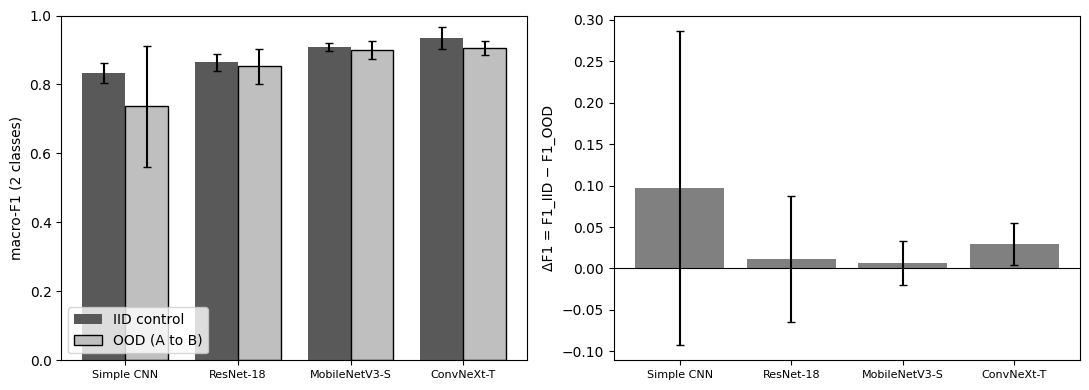

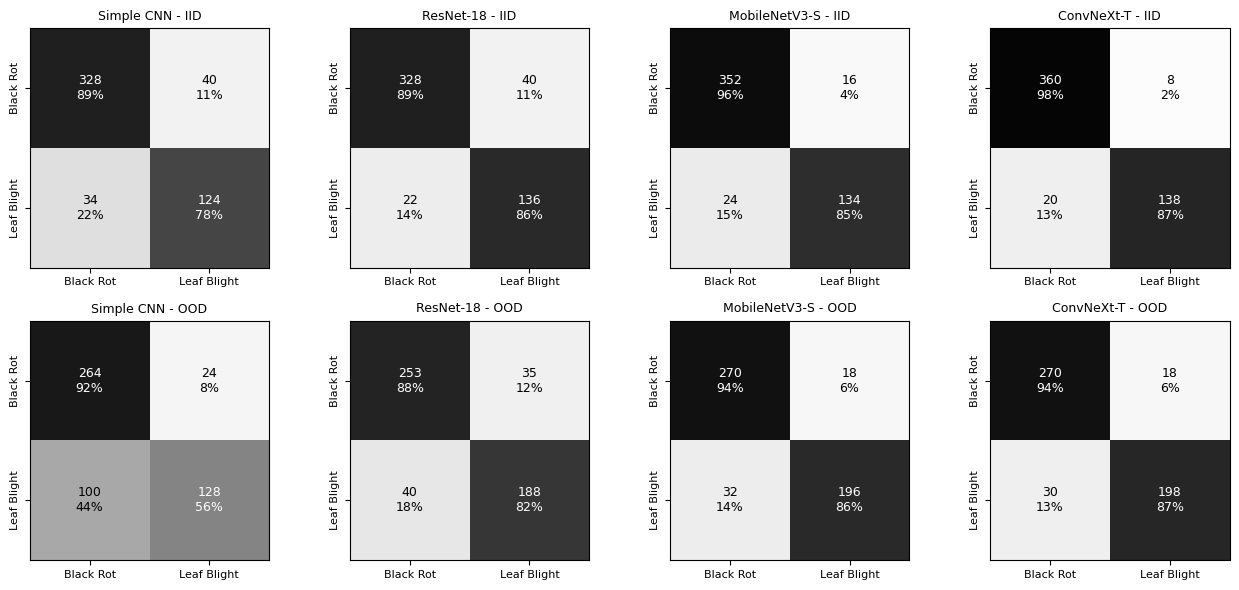

cm_br_br  cm_br_lb  cm_lb_br  cm_lb_lb
protocol model                                                     
iid      convnext_tiny            360         8        20       138
         mobilenet_v3_small       352        16        24       134
         resnet18                 328        40        22       136
         simple_cnn               328        40        34       124
ood_A2B  convnext_tiny            270        18        30       198
         mobilenet_v3_small       270        18        32       196
         resnet18                 253        35        40       188
         simple_cnn               264        24       100       128
ood_B2A  convnext_tiny           1232       808        64       632
         mobilenet_v3_small      1040      1000        86       610
         resnet18                1240       800        72       624
         simple_cnn               480      1560       124       572

In [35]:
LAB = {"simple_cnn": "Simple CNN", "resnet18": "ResNet-18", "mobilenet_v3_small": "MobileNetV3-S", "convnext_tiny": "ConvNeXt-T"}
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); xs = np.arange(len(MODELS)); w = 0.38
ax[0].bar(xs - w/2, rq1.f1_iid, w, yerr=rq1.f1_iid_std, label="IID control", color="0.35", capsize=3)
ax[0].bar(xs + w/2, rq1.f1_ood, w, yerr=rq1.f1_ood_std, label="OOD (A to B)", color="0.75", capsize=3, edgecolor="k")
ax[0].set_xticks(xs); ax[0].set_xticklabels([LAB[m] for m in MODELS], fontsize=8); ax[0].set_ylabel("macro-F1 (2 classes)"); ax[0].legend(); ax[0].set_ylim(0, 1)
ax[1].bar(xs, rq1.delta, yerr=rq1.delta_std, color="0.5", capsize=3); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xticks(xs); ax[1].set_xticklabels([LAB[m] for m in MODELS], fontsize=8); ax[1].set_ylabel("ΔF1 = F1_IID − F1_OOD")
plt.tight_layout(); plt.savefig(RES / "figures" / "fig_rq1_f1_and_delta.png", dpi=200); plt.show()

# confusion matrices, summed over the three seeds (rows = true, columns = predicted)
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for r, proto in enumerate(["iid", "ood_A2B"]):
    for c, name in enumerate(MODELS):
        d = runs[(runs.protocol == proto) & (runs.model == name)]
        cm = np.array([[d.cm_br_br.sum(), d.cm_br_lb.sum()], [d.cm_lb_br.sum(), d.cm_lb_lb.sum()]]); a = axes[r, c]
        a.imshow(cm / cm.sum(1, keepdims=True), cmap="Greys", vmin=0, vmax=1)
        for i in range(2):
            for j in range(2): a.text(j, i, f"{cm[i, j]}\n{100*cm[i, j]/cm[i].sum():.0f}%", ha="center", va="center", color="w" if cm[i, j] / cm[i].sum() > 0.5 else "k", fontsize=9)
        a.set_xticks([0, 1]); a.set_xticklabels(["Black Rot", "Leaf Blight"], fontsize=8); a.set_yticks([0, 1]); a.set_yticklabels(["Black Rot", "Leaf Blight"], fontsize=8, rotation=90, va="center")
        a.set_title(f"{LAB[name]} - {'IID' if proto == 'iid' else 'OOD'}", fontsize=9)
plt.tight_layout(); plt.savefig(RES / "figures" / "fig_rq1_confusion_iid_ood.png", dpi=200); plt.show()
cmt = runs.groupby(["protocol", "model"])[["cm_br_br", "cm_br_lb", "cm_lb_br", "cm_lb_lb"]].sum(); cmt.to_csv(RES / "tables" / "rq1_confusion_counts_sum_over_seeds.csv"); display(cmt)

## 10. Shortcut analysis (brief, Section C)

Two quantitative checks, then the failure audit.

(a) Can a phone be recognised from colour statistics alone, and does a colour-only classifier transfer across phones? (b) Do models that depend on the border (background) of the image lose more under the domain shift?

phone identity from colour only: accuracy 0.936 (majority = 0.841)


,mean,std
protocol,,
iid,0.685,0.027
ood_A2B,0.551,0.101


,test_macro_f1,f1_border_only,f1_centre_only,border_retention,delta_f1
model,,,,,
simple_cnn,0.834,0.354,0.640,0.424,0.097
resnet18,0.864,0.654,0.744,0.757,0.012
mobilenet_v3_small,0.908,0.539,0.749,0.594,0.007
convnext_tiny,0.935,0.810,0.893,0.867,0.029


Spearman(border_retention, delta_f1) over 4 models: -0.2 (n = 4: descriptive only)


R      G     B
domain label                          
A      Black Rot    141.2  143.0  76.7
       Leaf Blight  144.0  131.0  81.0
B      Black Rot    144.2  146.2  53.3
       Leaf Blight  140.7  137.1  73.0

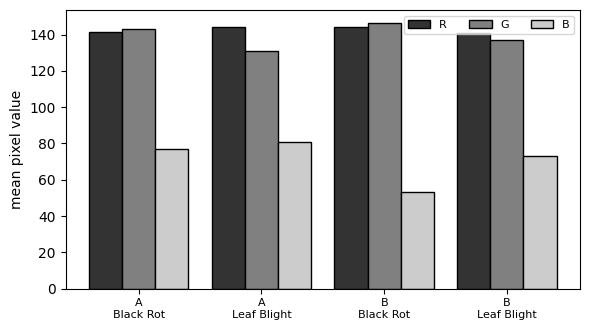

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score
def color_feats(Xs):
    out = []
    for i in range(0, len(Xs), 256):
        a = Xs[i:i + 256].astype(np.float32).reshape(-1, IMG * IMG, 3) / 255
        hist = np.array([np.concatenate([np.histogram(r[:, c], bins=8, range=(0, 1))[0] / r.shape[0] for c in range(3)]) for r in a])
        out.append(np.hstack([a.mean(1), a.std(1), hist]))
    return np.vstack(out)
FF = color_feats(X)

# (a1) phone identity from colour statistics, scene-grouped 5-fold CV
dom = (pool.domain.values == "B").astype(int); acc_cv = []
for tr_, te_ in GroupKFold(5).split(FF, dom, groups=cluster):
    acc_cv.append((RandomForestClassifier(300, random_state=0, n_jobs=-1).fit(FF[tr_], dom[tr_]).predict(FF[te_]) == dom[te_]).mean())
print(f"phone identity from colour only: accuracy {np.mean(acc_cv):.3f} (majority = {max(dom.mean(), 1 - dom.mean()):.3f})")
# (a2) colour-only disease classifier: IID control versus train A -> test B
sc_rows = []
for seed in SEEDS:
    for proto in ["iid", "ood_A2B"]:
        tr, va, te = SPLITS[(proto, seed)]; rf = RandomForestClassifier(300, random_state=seed, n_jobs=-1).fit(FF[tr], y[tr])
        sc_rows.append(dict(seed=seed, protocol=proto, macro_f1=f1_score(y[te], rf.predict(FF[te]), average="macro")))
colour_probe = pd.DataFrame(sc_rows).groupby("protocol").macro_f1.agg(["mean", "std"]); display(colour_probe.round(3))
colour_probe.to_csv(RES / "tables" / "shortcut_colour_probe.csv")
pd.DataFrame({"probe": ["phone identity from colour (grouped 5-fold accuracy)"], "value": [np.mean(acc_cv)]}).to_csv(RES / "tables" / "shortcut_phone_identity.csv", index=False)

# (b) border reliance versus drop: border-only macro-F1 on the IID test set, against delta F1
bor = runs[runs.protocol == "iid"].groupby("model")[["test_macro_f1", "f1_border_only", "f1_centre_only"]].mean().reindex(MODELS)
bor["border_retention"] = bor.f1_border_only / bor.test_macro_f1; bor["delta_f1"] = rq1.delta
display(bor.round(3)); bor.to_csv(RES / "tables" / "shortcut_border_vs_delta.csv")
print("Spearman(border_retention, delta_f1) over 4 models:", round(spearmanr(bor.border_retention, bor.delta_f1).statistic, 2), "(n = 4: descriptive only)")

# (c) colour cast per phone and class
cast = pd.DataFrame(X.reshape(len(X), -1, 3).mean(1), columns=list("RGB")).assign(domain=pool.domain.values, label=pool.label.values)
display(cast.groupby(["domain", "label"]).mean().round(1)); cast.groupby(["domain", "label"]).mean().to_csv(RES / "tables" / "shortcut_mean_rgb.csv")
fig, ax = plt.subplots(figsize=(6, 3.4)); g = cast.groupby(["domain", "label"])[list("RGB")].mean(); n = len(g)
for k, ch in enumerate("RGB"): ax.bar(np.arange(n) + (k - 1) * 0.27, g[ch], 0.27, label=ch, color=["0.2", "0.5", "0.8"][k], edgecolor="k")
ax.set_xticks(range(n)); ax.set_xticklabels([f"{d}\n{l}" for d, l in g.index], fontsize=8); ax.set_ylabel("mean pixel value"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(RES / "figures" / "fig_colour_cast_by_phone.png", dpi=200); plt.show()

## 11. Failure audit: at least 20 cases to inspect by hand

The best OOD model (highest mean OOD macro-F1, seed 42) is audited; if it has fewer than 30 errors, errors of the other models are added. **Open the gallery, look at each image, and fill `manual_cause` / `manual_notes` in `failure_audit_template.csv`** (for example: background soil, camera colour cast, hand in frame, motion blur, ambiguous lesion, possible label noise). The causes in the report must come from your own inspection.

audited model: convnext_tiny
30 failure cases written; distinct scenes: 5


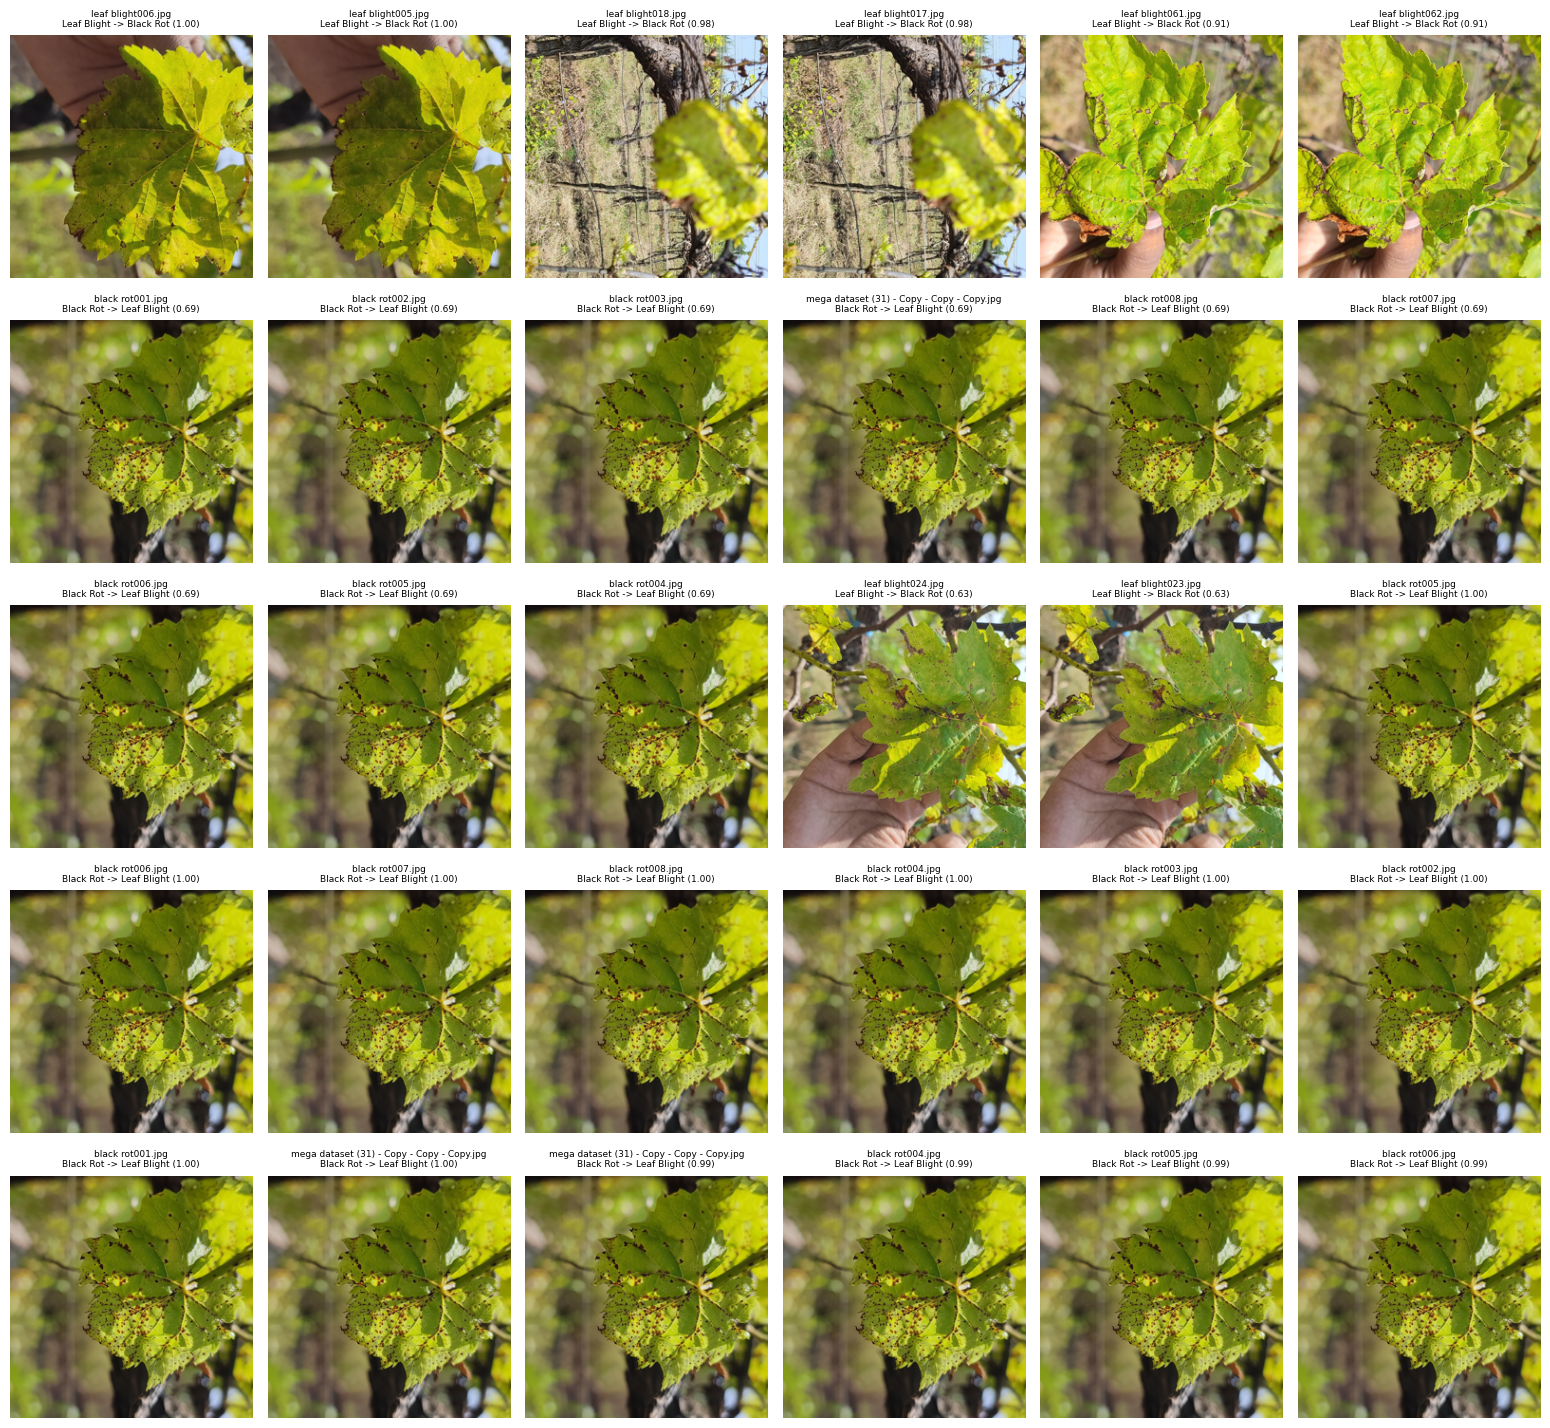

In [37]:
best = rq1.f1_ood.idxmax(); print("audited model:", best)
Pt = pd.read_csv(PRED_CSV); Pt = Pt[(Pt.split == "test") & (Pt.protocol == "ood_A2B") & (Pt.seed == SEEDS[0])]
Pt["conf"] = Pt[["prob_black_rot", "prob_leaf_blight"]].max(1); Pt["wrong"] = Pt.true_label != Pt.pred_label
err = Pt[Pt.wrong & (Pt.model == best)].sort_values("conf", ascending=False)
if len(err) < 30: err = pd.concat([err, Pt[Pt.wrong & (Pt.model != best)].sort_values("conf", ascending=False)]).drop_duplicates(["sample_id", "model"])
err = err.head(30).merge(pool[["sample_id", "path", "cluster"]], on="sample_id")
meanrgb = dict(zip(pool.sample_id, X.reshape(len(X), -1, 3).mean(1).round(1).tolist()))
audit = err[["sample_id", "filename", "model", "domain_device", "true_label", "pred_label", "conf", "cluster"]].copy()
audit[["mean_R", "mean_G", "mean_B"]] = [meanrgb[s] for s in audit.sample_id]; audit["manual_cause"] = ""; audit["manual_notes"] = ""
audit.round(3).to_csv(RES / "tables" / "failure_audit_template.csv", index=False); print(len(audit), "failure cases written; distinct scenes:", audit.cluster.nunique())
n = len(err); cols = 6; rows_ = int(np.ceil(n / cols)); fig, axes = plt.subplots(rows_, cols, figsize=(cols * 2.6, rows_ * 2.9))
for a in np.ravel(axes): a.axis("off")
for a, (_, r) in zip(np.ravel(axes), err.iterrows()):
    a.imshow(Image.open(r.path).convert("RGB").resize((256, 256))); a.set_title(f"{r.filename}\n{r.true_label} -> {r.pred_label} ({r.conf:.2f})", fontsize=6.5)
plt.tight_layout(); plt.savefig(RES / "figures" / "fig_ood_failure_gallery.png", dpi=170); plt.show()

## 12. Export: environment record and the final prediction file

In [38]:
import sklearn, scipy
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
env = f"""# Environment

* Hardware: {gpu}
* Python {sys.version.split()[0]} on {platform.platform()}
* torch {torch.__version__}, torchvision {torchvision.__version__}, numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}, scipy {scipy.__version__}
* Seeds: {SEEDS} (training seed and split seed; the OOD test domain is fixed)
* Image size {IMG}, batch {BATCH}, flips-only augmentation, AdamW with cosine schedule
* Pretrained checkpoints: torchvision IMAGENET1K_V1 weights for ResNet-18, MobileNetV3-Small and ConvNeXt-Tiny
* Wall-clock training time per run: results/tables/rq1_runs.csv (column train_time_s); total {runs.train_time_s.sum() / 60:.1f} min
"""
(RES / "environment.md").write_text(env); print(env)
P = pd.read_csv(PRED_CSV)
cols = ["sample_id", "true_label", "pred_label", "prob_healthy", "prob_black_rot", "prob_esca", "prob_leaf_blight", "domain_device", "domain_lighting"]
P[cols + [c for c in P.columns if c not in cols]].to_csv(PRED_CSV, index=False)
print("predictions:", len(P), "rows | required columns first:", cols)
# Drive keeps Google-Sheet shortcuts (.gsheet/.gdoc) that cannot be zipped; skip them and the Midterm folder.
import zipfile
with zipfile.ZipFile(WORK / "final_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in RES.rglob("*"):
        if f.is_file() and f.suffix not in (".gsheet", ".gdoc") and "midterm" not in f.parts:
            z.write(f, f.relative_to(RES))
print("zip:", WORK / "final_results.zip")

# Environment

* Hardware: Tesla T4
* Python 3.13.16 on Linux-6.6.159+-x86_64-with-glibc2.39
* torch 2.14.1+cu130, torchvision 0.29.1+cu130, numpy 2.4.6, pandas 2.2.3, scikit-learn 1.6.1, scipy 1.16.3
* Seeds: [42, 43, 44] (training seed and split seed; the OOD test domain is fixed)
* Image size 224, batch 16, flips-only augmentation, AdamW with cosine schedule
* Pretrained checkpoints: torchvision IMAGENET1K_V1 weights for ResNet-18, MobileNetV3-Small and ConvNeXt-Tiny
* Wall-clock training time per run: results/tables/rq1_runs.csv (column train_time_s); total 6.4 min

predictions: 19548 rows | required columns first: ['sample_id', 'true_label', 'pred_label', 'prob_healthy', 'prob_black_rot', 'prob_esca', 'prob_leaf_blight', 'domain_device', 'domain_lighting']
